# Code execution and the Files API

Upload `streaming.csv`, let Claude analyze it in a remote sandbox, then download
the generated report and plot. The local notebook orchestrates requests; it does
not execute the model's generated code.

The lesson uses Anthropic's `code_execution_20250825` tool with a
`container_upload` message block. We test that schema first. On the configured
OpenRouter endpoint it is rejected, while file upload works. The practical run
therefore uses OpenRouter's `openrouter:shell` server tool and attaches the file
through `environment.file_ids`. This is a provider-specific adaptation, not a
successful test of Anthropic's native execution tool.

Shell results include a container ID and generated file references. Promote the
outputs into Files API storage, download them, and delete only the workspace
files created by this run. Container copies have their provider-managed lifetime.

## Setup and Files API helpers

Use the same model and API key as the preceding notebook. Keep the original CSV
locally: uploaded inputs are not downloadable, whereas generated outputs are.
A raw JSON response preserves OpenRouter's extra server-tool result types.

In [1]:
import csv
import json
from pathlib import Path
from urllib.parse import urlparse, quote
from uuid import uuid4
from xml.etree import ElementTree

import httpx
from anthropic import Anthropic, APIStatusError
from dotenv import load_dotenv
from IPython.display import SVG, display

load_dotenv()
client = Anthropic(
    timeout=240.0,
    max_retries=0,
    default_headers={"anthropic-beta": "files-api-2025-04-14"},
)
model = "claude-sonnet-4-5"
assert urlparse(str(client.base_url)).hostname == "openrouter.ai", (
    "The practical sandbox section below is configured for OpenRouter."
)
api_base = str(client.base_url).rstrip("/") + "/v1"
output_dir = Path("code_execution_output")
output_dir.mkdir(exist_ok=True)
created_file_ids = []


def upload(file_path):
    path = Path(file_path)
    with path.open("rb") as file:
        metadata = client.beta.files.upload(file=(path.name, file, "text/csv"))
    created_file_ids.append(metadata.id)
    return metadata


def get_metadata(file_id):
    return client.beta.files.retrieve_metadata(file_id)


def download_file(file_id, filename):
    content = client.beta.files.download(file_id)
    content.write_to_file(filename)
    return Path(filename)


def delete_file(file_id):
    return client.beta.files.delete(file_id)


def container_request(method, path):
    # This SDK has Files API helpers, but no OpenRouter containers resource.
    with httpx.Client(timeout=60.0) as http:
        response = http.request(
            method, f"{api_base}/containers/{path}",
            headers={"Authorization": f"Bearer {client.api_key}"},
        )
        response.raise_for_status()
        return response.json()


def promote_file(container_id, file_id):
    metadata = container_request(
        "POST", f"{quote(container_id, safe='')}/files/{quote(file_id, safe='')}/promote"
    )
    created_file_ids.append(metadata["id"])
    return metadata


def chat(messages, tools, max_tokens=6000):
    raw = client.messages.with_raw_response.create(
        model=model, max_tokens=max_tokens, messages=messages, tools=tools,
    )
    return raw.http_response.json()


def print_response(response):
    for block in response.get("content", []):
        if block["type"] == "text":
            print(block["text"])
        elif block["type"] == "server_tool_use":
            print(f"\n[server tool: {block['name']}]")
        else:
            print(json.dumps(block, indent=2))
    print("\nUsage:", json.dumps(response.get("usage", {}), indent=2))


def chat_stream(messages, tools, max_tokens=6000):
    # Collect SSE directly: the SDK does not define OpenRouter's shell result type.
    message, blocks, partial_json = {}, {}, {}
    complete = False
    with httpx.Client(timeout=240.0) as http:
        with http.stream(
            "POST", f"{api_base}/messages",
            headers={"Authorization": f"Bearer {client.api_key}",
                     "anthropic-version": "2023-06-01"},
            json={"model": model, "max_tokens": max_tokens, "stream": True,
                  "messages": messages, "tools": tools},
        ) as response:
            response.raise_for_status()
            for line in response.iter_lines():
                if not line.startswith("data: ") or line == "data: [DONE]":
                    continue
                event = json.loads(line[6:])
                kind = event["type"]
                if kind == "error":
                    raise RuntimeError(event["error"])
                if kind == "message_start":
                    message = event["message"]
                elif kind == "content_block_start":
                    blocks[event["index"]] = event["content_block"]
                elif kind == "content_block_delta":
                    index, delta = event["index"], event["delta"]
                    if delta["type"] == "text_delta":
                        blocks[index]["text"] += delta["text"]
                    elif delta["type"] == "input_json_delta":
                        partial_json[index] = partial_json.get(index, "") + delta["partial_json"]
                    else:
                        raise ValueError(f"Unexpected stream delta: {delta['type']}")
                elif kind == "content_block_stop":
                    index = event["index"]
                    if partial_json.get(index):
                        blocks[index]["input"] = json.loads(partial_json[index])
                elif kind == "message_delta":
                    message.update(event["delta"])
                    message.setdefault("usage", {}).update(event.get("usage", {}))
                elif kind == "message_stop":
                    complete = True
    assert complete, "Response stream ended before message_stop"
    message["content"] = [blocks[index] for index in sorted(blocks)]
    return message


## Probe the native tool

A normal text answer is not proof of code execution. On this endpoint the native
tool type returns HTTP 400 with `Unknown server-tool shorthand`. Print only
validation details; keep authentication and request headers out of outputs.

In [2]:
native_response = None
try:
    native_response = chat(
        [{"role": "user", "content": "Use code execution to calculate 12345 * 6789."}],
        [{"type": "code_execution_20250825", "name": "code_execution"}],
        max_tokens=500,
    )
    print_response(native_response)
except APIStatusError as error:
    print(f"Native code execution request: HTTP {error.status_code}")
    body = error.body if isinstance(error.body, dict) else {}
    details = body.get("metadata", {}).get("raw", "")
    print(details.replace(client.api_key, "[REDACTED]"))

Native code execution request: HTTP 400
[
  {
    "code": "custom",
    "path": [
      "tools",
      0,
      "type"
    ],
    "message": "Unknown server-tool shorthand"
  }
]


## Upload and analyze the CSV

The sandbox receives a copy of the uploaded file. Ask for a reproducible count,
a short observational analysis, and an SVG plot using Python's standard library
so the run does not depend on installing packages or enabling network access.
SVG is a downloadable chart just like a PNG, and Jupyter can display it inline.

The tool executes on OpenRouter (`engine="openrouter"`). Do not replace it with
a local shell executor. Associations in this dataset do not establish causes.

Use streaming for the longer remote analysis; collect text, tool calls, server
results and final usage without discarding provider-specific blocks.

In [3]:
file_metadata = None
analysis_response = None
generated_files = []
try:
    file_metadata = upload("streaming.csv")
    print(get_metadata(file_metadata.id).model_dump_json(indent=2))
    execution_tool = {
        "type": "openrouter:shell",
        "parameters": {
            "engine": "openrouter",
            "environment": {
                "type": "container_reference",
                "container_id": "academy_" + uuid4().hex[:20],
                "file_ids": [file_metadata.id],
            },
        },
    }
    prompt = """Use the shell tool to analyze the attached streaming CSV.
You must execute Python code, not estimate numbers from memory. Work in your home
working directory. The input is named with an ID prefix followed by -streaming.csv;
locate it with pathlib.Path.home().glob('*streaming.csv'). Use standard-library
Python (csv, json, statistics, xml.sax.saxutils); do not install anything.

Determine row count, churned count, churn fraction, churn by SubscriptionTier and
by CustomerServiceInteractionsLastYear. Briefly discuss observed associations,
not causal drivers. Generate exactly these two outputs in the home directory:
1. summary.json: keys rows (int), churned (int), churn_rate (fraction 0..1),
   by_subscription_tier and by_support_interactions (each a list of objects with
   group (string), rows (int), churned (int), churn_rate (fraction 0..1)).
2. churn_analysis.svg: a readable SVG with two labelled bar-chart panels showing
   churn percentages by tier and support interactions. Use a white background,
   clear axes, category names, percent labels, and ample margins. Escape XML text.
Print the summary JSON to stdout after writing both files. Prefer one Python
script in a heredoc; imports and variables do not survive separate commands.
Use valid JSON tool arguments with commands as an array of strings. Keep your
final answer concise. Do not create extra files or use network access."""
    analysis_response = chat_stream(
        [{"role": "user", "content": prompt}], [execution_tool],
    )
    (output_dir / "analysis_response.json").write_text(json.dumps(analysis_response, indent=2))
    print_response(analysis_response)
finally:
    # Delete our input even if the analysis fails; container copies are independent.
    if file_metadata is not None:
        delete_file(file_metadata.id)
        created_file_ids.remove(file_metadata.id)
        print("Deleted this run's uploaded input from workspace storage.")

{
  "id": "or_file_0VZcvYW5l2h0LzXQ4DmUjpXq",
  "created_at": "2026-10-31T11:46:10.404000Z",
  "filename": "streaming.csv",
  "mime_type": "text/csv",
  "size_bytes": 25733,
  "type": "file",
  "downloadable": false,
  "scope": null,
  "_shape": "anthropic"
}


I'll analyze the streaming CSV file by creating a Python script to process the data and generate the required outputs.

[server tool: openrouter:shell]
{
  "type": "openrouter_shell_tool_result",
  "tool_use_id": "toolu_bdrk_01VZLrJwR6cMFZ8jkNffFi5f",
  "content": {
    "output": [
      {
        "stdout": "{\n  \"rows\": 500,\n  \"churned\": 0,\n  \"churn_rate\": 0.0,\n  \"by_subscription_tier\": [\n    {\n      \"group\": \"Basic\",\n      \"rows\": 207,\n      \"churned\": 0,\n      \"churn_rate\": 0.0\n    },\n    {\n      \"group\": \"Premium\",\n      \"rows\": 83,\n      \"churned\": 0,\n      \"churn_rate\": 0.0\n    },\n    {\n      \"group\": \"Standard\",\n      \"rows\": 210,\n      \"churned\": 0,\n      \"churn_rate\": 0.0\n    }\n  ],\n  \"by_support_interactions\": [\n    {\n      \"group\": \"0\",\n      \"rows\": 8,\n      \"churned\": 0,\n      \"churn_rate\": 0.0\n    },\n    {\n      \"group\": \"1\",\n      \"rows\": 66,\n      \"churned\": 0,\n      \"churn_rate

Deleted this run's uploaded input from workspace storage.


## Download generated outputs

Use file IDs from actual server results, not IDs written in the model's prose.
Promote each container output, download through Files API, then remove its
workspace copy. Keep the local result for inspection.

In [4]:
assert analysis_response is not None
assert analysis_response["stop_reason"] == "end_turn", "Analysis did not finish"
server_results = [b for b in analysis_response["content"]
                  if b["type"] == "openrouter_shell_tool_result"]
assert server_results, "No server execution results returned"
expected_names = {"summary.json", "churn_analysis.svg"}
references = {}
for block in server_results:
    for ref in block.get("files", []):
        name = Path(ref["filename"]).name
        if name in expected_names:
            references[name] = (ref.get("container_id", block.get("container_id")), ref["file_id"])
assert set(references) == expected_names, f"Missing generated outputs: {expected_names - set(references)}"

for name, (container_id, file_id) in references.items():
    metadata = promote_file(container_id, file_id)
    try:
        assert metadata["downloadable"]
        path = download_file(metadata["id"], output_dir / name)
        assert path.stat().st_size > 0
        generated_files.append(path)
        print(f"Downloaded {path}: {path.stat().st_size:,} bytes")
    finally:
        delete_file(metadata["id"])
        created_file_ids.remove(metadata["id"])
assert not created_file_ids

Downloaded code_execution_output/churn_analysis.svg: 4,560 bytes


Downloaded code_execution_output/summary.json: 1,226 bytes


## Verify the result against the local input

Independently recompute counts and grouped rates from the CSV, and compare every
group with the downloaded JSON. This checks the actual server-generated artifact,
not just the model's final answer. Display the downloaded SVG below.

Verified 500 rows, 193 churned (38.6%), and every group rate.


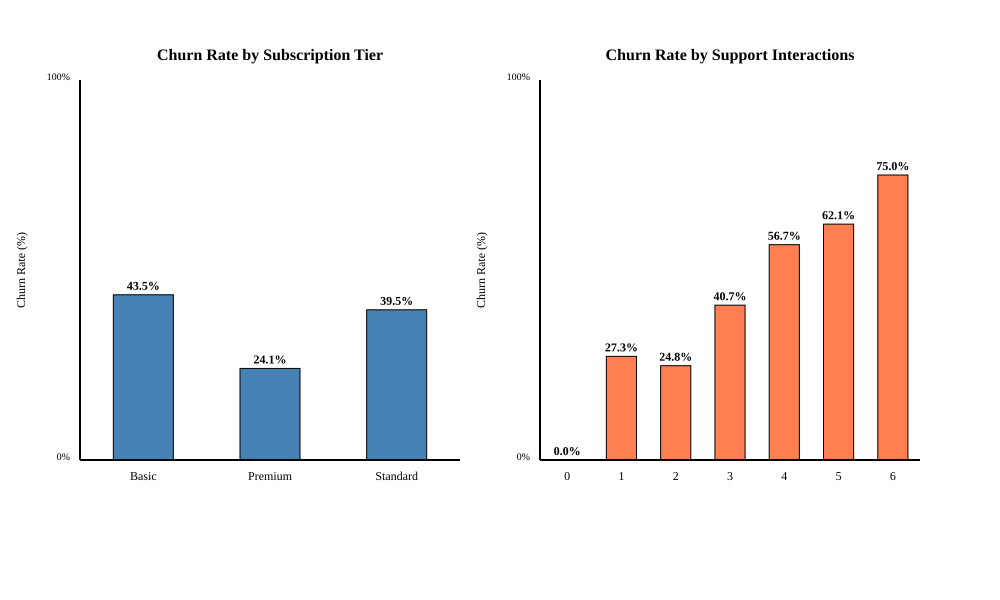

In [5]:
with Path("streaming.csv").open(newline="") as file:
    rows = list(csv.DictReader(file))
summary = json.loads((output_dir / "summary.json").read_text())
churned = sum(int(row["Churned"]) for row in rows)
assert summary["rows"] == len(rows)
assert summary["churned"] == churned
assert abs(summary["churn_rate"] - churned / len(rows)) < 1e-6

for field, key in [
    ("SubscriptionTier", "by_subscription_tier"),
    ("CustomerServiceInteractionsLastYear", "by_support_interactions"),
]:
    actual = {str(item["group"]): item for item in summary[key]}
    assert len(actual) == len(summary[key]), "Duplicate groups"
    assert set(actual) == {row[field] for row in rows}
    for group, item in actual.items():
        members = [row for row in rows if row[field] == group]
        count = sum(int(row["Churned"]) for row in members)
        assert item["rows"] == len(members)
        assert item["churned"] == count
        assert abs(item["churn_rate"] - count / len(members)) < 1e-6

root = ElementTree.parse(output_dir / "churn_analysis.svg").getroot()
assert root.tag == "{http://www.w3.org/2000/svg}svg"
assert not any(node.tag.endswith("}script") for node in root.iter())
print(f"Verified {len(rows)} rows, {churned} churned ({churned / len(rows):.1%}), and every group rate.")
display(SVG(filename=str(output_dir / "churn_analysis.svg")))

The successful practical path here is OpenRouter Files API plus its hosted shell.
It does not prove support for Anthropic's native `code_execution` or
`container_upload` interface. Uploaded inputs and promoted workspace outputs from
this run are deleted after use; downloaded results remain in `code_execution_output/`.

Next: quiz on features of Claude, then Model Context Protocol.